In [1]:
pip install numpy matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


f1 | n = 3 | erreur max : Lagrange = 0.611269074886216 | Newton = 0.6112690748862173 | Hermite = 0.1296956789658008
f1 | n = 5 | erreur max : Lagrange = 0.08883653432863792 | Newton = 0.08883653432863614 | Hermite = 0.0002614331289443328
f1 | n = 9 | erreur max : Lagrange = 0.00036604668275597163 | Newton = 0.0003660466827613007 | Hermite = 4.352873617108344e-11
f1 | n = 15 | erreur max : Lagrange = 7.0645995720042265e-09 | Newton = 7.0645373995148475e-09 | Hermite = 6.963318810448982e-13


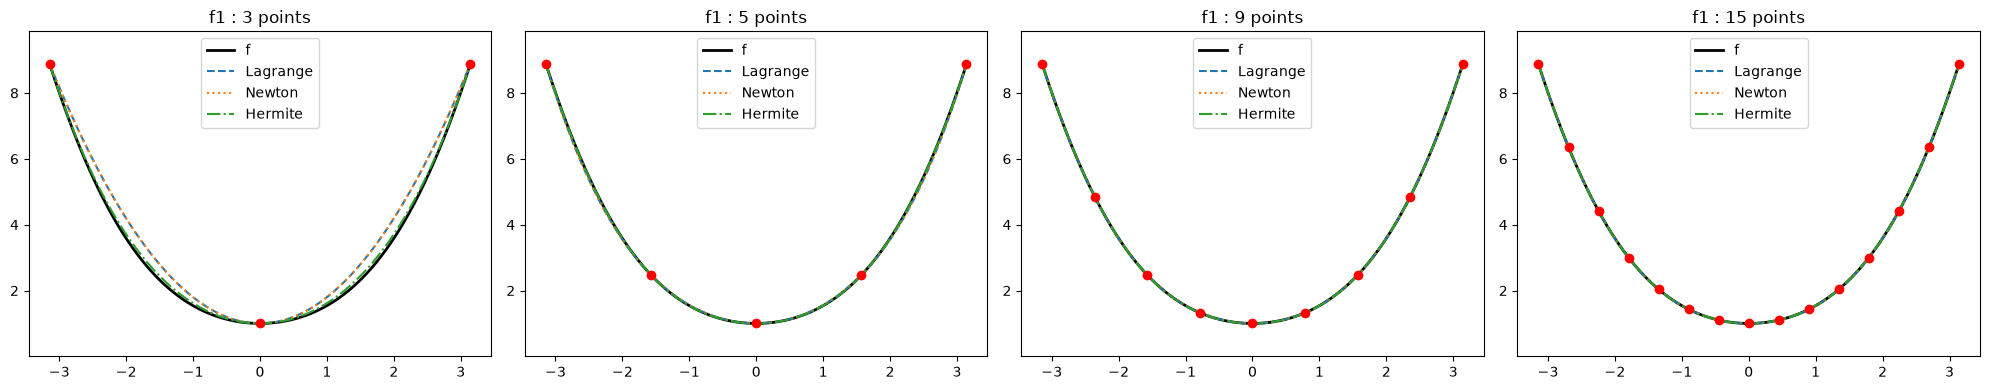

f2 | n = 3 | erreur max : Lagrange = 0.1645070606350043 | Newton = 0.16450706063500442 | Hermite = 0.10150979937078553
f2 | n = 5 | erreur max : Lagrange = 0.09038666408561938 | Newton = 0.09038666408561936 | Hermite = 0.02196213497525562
f2 | n = 9 | erreur max : Lagrange = 0.06263272351428847 | Newton = 0.06263272351428815 | Hermite = 0.009898097517177393
f2 | n = 15 | erreur max : Lagrange = 0.05742655295630318 | Newton = 0.05742655295630569 | Hermite = 0.008179515870606432


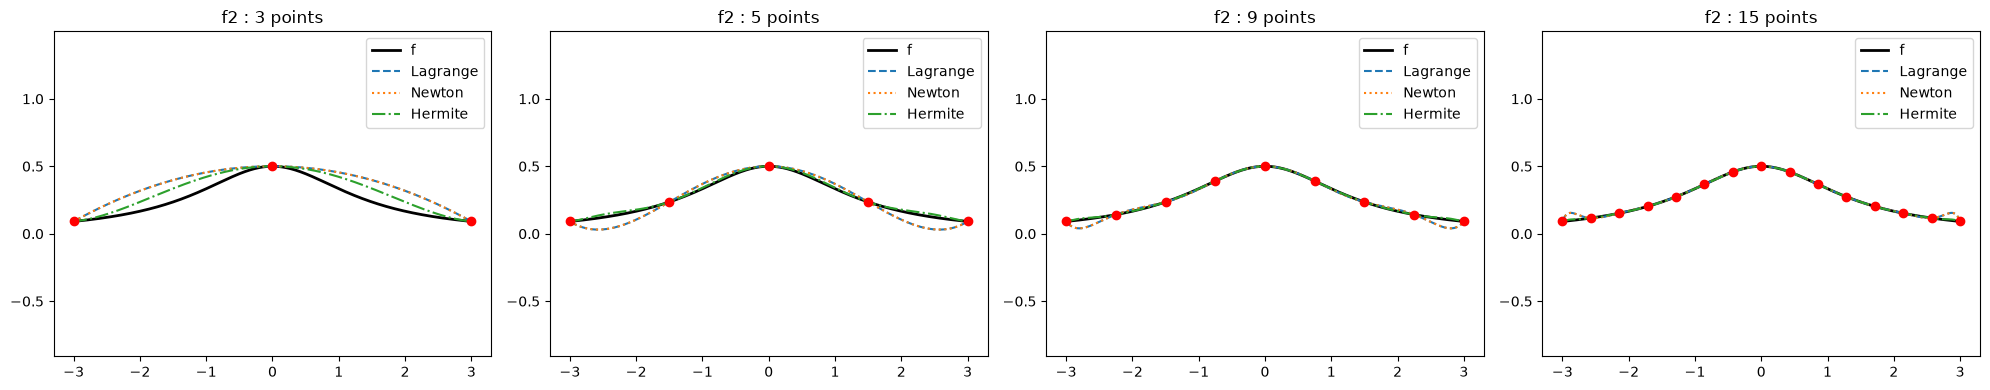

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# == functions ==
def f1(x):
    return np.cos(x) + x**2

def df1(x):
    return -np.sin(x) + 2*x

def f2(x):
    return 1 / (x**2 + 2)

def df2(x):
    return -2*x / (x**2 + 2)**2


# == LAGRANGE ==
def lagrange(x, y, t):
    n = len(x)
    P = np.zeros(len(t))
    for i in range(n):
        L = np.ones(len(t))
        for j in range(n):
            if j != i:
                L = L * (t - x[j]) / (x[i] - x[j])
        P = P + y[i] * L
    return P


# == NEWTON ==
def newton(x, y, t):
    n = len(x)
    table = np.zeros((n, n))

    for i in range(n):
        table[i, 0] = y[i]

    for j in range(1, n):
        for i in range(n - j):
            table[i, j] = (table[i+1, j-1] - table[i, j-1]) / (x[i+j] - x[i])

    P = np.zeros(len(t))
    produit = np.ones(len(t))
    for k in range(n):
        P = P + table[0, k] * produit
        produit = produit * (t - x[k])
    return P


# == HERMITE ==
def hermite(x, y, dy, t):
    n = len(x)
    m = 2 * n                      
    z = np.zeros(m)
    table = np.zeros((m, m))

    for i in range(m):
        z[i] = x[i // 2]
        table[i, 0] = y[i // 2]

    for i in range(m - 1):
        if z[i] == z[i+1]:
            table[i, 1] = dy[i // 2]
        else:
            table[i, 1] = (table[i+1, 0] - table[i, 0]) / (z[i+1] - z[i])

    for j in range(2, m):
        for i in range(m - j):
            table[i, j] = (table[i+1, j-1] - table[i, j-1]) / (z[i+j] - z[i])

    P = np.zeros(len(t))
    produit = np.ones(len(t))
    for k in range(m):
        P = P + table[0, k] * produit
        produit = produit * (t - z[k])
    return P


# == CALCULS + GRAPHES ==
def etude(f, df, a, b, nom, liste_n):
    t = np.linspace(a, b, 1000)
    plt.figure(figsize=(5 * len(liste_n), 4))

    for idx in range(len(liste_n)):
        npts = liste_n[idx]
        x = np.linspace(a, b, npts)
        y = f(x)
        dy = df(x)

        PL = lagrange(x, y, t)
        PN = newton(x, y, t)
        PH = hermite(x, y, dy, t)

        plt.subplot(1, len(liste_n), idx + 1)
        plt.plot(t, f(t), 'k', linewidth=2, label='f')
        plt.plot(t, PL, '--', label='Lagrange')
        plt.plot(t, PN, ':', label='Newton')
        plt.plot(t, PH, '-.', label='Hermite')
        plt.plot(x, y, 'ro')
        plt.ylim(np.min(f(t)) - 1, np.max(f(t)) + 1)
        plt.title(nom + " : " + str(npts) + " points")
        plt.legend()

        eL = np.max(np.abs(f(t) - PL))
        eN = np.max(np.abs(f(t) - PN))
        eH = np.max(np.abs(f(t) - PH))
        print(nom, "| n =", npts, "| erreur max : Lagrange =", eL,
              "| Newton =", eN, "| Hermite =", eH)

    plt.tight_layout()
    plt.show()


etude(f1, df1, -np.pi, np.pi, "f1", [3, 5, 9, 15])
etude(f2, df2, -3, 3, "f2", [3, 5, 9, 15])